## **MScFE 690 Capstone Project**
## **Group 17836: Engineering an Investable Australian Volatility ETF**


In [1]:
import importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import seaborn as sns
import warnings

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.cross_decomposition import PLSRegression
from sklearn.pipeline import Pipeline
from sklearn.linear_model import ElasticNetCV

from hmmlearn import hmm
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)


warnings.filterwarnings("ignore")

SEED = 42

START_DATE = "2011-01-01"
END_DATE = "2026-09-15"
TRN_WINDOW = 252
TST_WINDOW = 10

HMM_STATES = 3

PLT_STRT = 1900 #0
PLT_SIZE = 300  #4000

### **Overview**
As part of our M2 project proposal submission, we outlined the code high level design steps which can be summarised as follows:
1. Data processing
2. Screening and elimination
3. Sliding window Walk-forward loop:

    3.1 Sliding window Walk-forward loop: Principal Component Regression (PCR)
   
    3.2 Sliding window Walk-forward loop: Partial Least Squares (PLS)
   
    3.3 Sliding window Walk-forward loop: Elastic Net Regression (EN)
   
5. Hidden Markov Model
6. Expanding window Walk-forward loop for HMM

In the next sections we will outline and implement each of these steps in details.

In [2]:
# Fady: Define reusable util functions

def walk_forward_sliding_window(dataset_length, train_window_size, test_window_size):
    splits = []
    train_start = 0

    while True:
        train_end = train_start + train_window_size - 1
        test_start = train_end + 1
        test_end = test_start + test_window_size - 1

        if test_end >= dataset_length:
            break

        splits.append(
            {
                "train_start": train_start,
                "train_end": train_end,
                "test_start": test_start,
                "test_end": test_end,
            }
        )

        # slide both train and test windows forward
        train_start += test_window_size

    return pd.DataFrame(splits)

def walk_forward_expanding_window(dataset_length, initial_train_window_size, test_window_size):
    splits = []
    train_end = initial_train_window_size - 1

    while True:
        test_start = train_end + 1
        test_end = test_start + test_window_size - 1

        if test_end >= dataset_length:
            break

        splits.append(
            {
                "train_start": 0,
                "train_end": train_end,
                "test_start": test_start,
                "test_end": test_end,
            }
        )

        # expand training window
        train_end += test_window_size

    return pd.DataFrame(splits)


def download_adjusted_prices(tickers, start, end):
    raw = yf.download( tickers,start=start, end=end, auto_adjust=False,actions=False, 
                      progress=False, group_by="column", threads=True )
    if raw.empty:
        raise RuntimeError("No price data were downloaded. Check internet access and ticker symbols.")

    if isinstance(raw.columns, pd.MultiIndex):
        fields = raw.columns.get_level_values(0)
        if "Adj Close" in fields:
            prices = raw["Adj Close"].copy()
        elif "Close" in fields:
            prices = raw["Close"].copy()
        else:
            raise RuntimeError("Could not find Adj Close or Close in Yahoo Finance output.")
    else:
        col = "Adj Close" if "Adj Close" in raw.columns else "Close"
        prices = raw[[col]].rename(columns={col: tickers[0]})

    prices = prices.sort_index().reindex(columns=tickers)
    missing_cols = [c for c in tickers if c not in prices.columns]
    if missing_cols:
        raise RuntimeError(f"Missing downloaded tickers: {missing_cols}")

    #prices = prices.ffill().dropna(how="any")
    return prices


def download_aud_usd(start_date=START_DATE, end_date=END_DATE):
    #Download AUD/USD Exchange Rate
    download_end = (pd.Timestamp(end_date) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")

    prices = yf.download(
        "AUDUSD=X",
        start=start_date,
        end=download_end,
        auto_adjust=False,
        progress=False,
    )


    if prices.empty:
        raise ValueError("AUD/USD exchange-rate data could not be downloaded.")

    if "AUDUSD=X" in prices.columns:
        fx = prices["AUDUSD=X"].copy()
    else:
        fx = prices.iloc[:, 0].copy()

    fx.name = "AUDUSD"

    return fx

def convert_us_to_aud(price_df, aud_usd_series, us_tickers):
    """
        Price_AUD = Price_USD / AUDUSD
    """
    converted_df = price_df.copy()

    fx = aud_usd_series.reindex(converted_df.index).ffill(limit=20)

    for ticker in us_tickers:
        if ticker in converted_df.columns:
            converted_df[ticker] = converted_df[ticker] / fx

    return converted_df

def get_ranked_pairwise_correlations(corr_matrix):
    """Returns unique pairwise correlations sorted highest to lowest."""
    mask = np.triu(
        np.ones(corr_matrix.shape, dtype=bool),
        k=1,
    )

    corr_pairs = corr_matrix.where(mask).stack()
    corr_pairs.index.names = ["Ticker_1", "Ticker_2"]
    corr_pairs = corr_pairs.sort_values(ascending=False)

    return corr_pairs


def sliding_walk_forward_reconst(y_pred,orig_price,train_window_size,test_window_size):
    
    '''
    reconstruct A-VIX prices from A-VIX precentage change predictions
    '''
    
    reconst= list(orig_price.values[0]*np.cumprod(1+y_pred[0:train_window_size]))
        
    splits=walk_forward_sliding_window(len(y_pred), train_window_size, test_window_size)
    
    for idx in range(len(splits)):
        
        offsets= list(splits.loc[idx].values)
        trn_s = offsets[0]
        trn_e = offsets[1]
        tst_s = offsets[2]
        tst_e = offsets[3]
        
        segment = list(orig_price.values[tst_s]*np.cumprod(1+y_pred[tst_s:tst_e+1]))
        reconst.extend(segment)
    
    return np.clip(reconst,0,100)

def focused_plot(title,reconstructed,orig_price,strt=PLT_STRT,sz=PLT_SIZE):
    # Zoom in window for visual assessment
    plt.clf()
    plt.figure(figsize=(12,5))
    plt.plot(orig_price.values[strt:strt+sz], label='Actual', linewidth=2)
    plt.plot(reconstructed[strt:strt+sz], label= title+' Predicted', alpha=0.8)
    plt.legend()
    plt.title("Actual vs "+title)
    plt.show()

### **1. Data Processing**
- Download all candidate securities from the invetsment universe (Jan 2019 – Sep 2026)
- Align dates for US: The prices observed in Australia can only be upto the previous day in US.
- Convert USD prices to AUD at daily exchange rate for US securties.
- handle missing data
- compute A-VIX daily percentage change 
- Compute securties daily returns
- Standardize returns



In [3]:
#Investment Universe
tickers_dict = pd.read_csv('investment_universe_dictionary.csv')
US_TICKERS = list(tickers_dict[tickers_dict.Region=='US']['Ticker'].values)
AU_TICKERS = list(tickers_dict[tickers_dict.Region=='AU']['Ticker'].values)
ALL_TICKERS = list(tickers_dict['Ticker'].values)


display(tickers_dict)


universe_prices= download_adjusted_prices(ALL_TICKERS, START_DATE, END_DATE)

# Fady: Australia can only observe the previous day in US
for clm in US_TICKERS:
    universe_prices[clm] = universe_prices[clm].shift(1)
    
    
aud_usd = download_aud_usd(start_date=START_DATE, end_date=END_DATE)
universe_aud_prices = convert_us_to_aud(universe_prices, aud_usd, US_TICKERS )

print('\n\n')
display(universe_aud_prices)

,Ticker,Description,Region,Inception_Date
0,^AXVI,S&P/ASX 200 VIX Index,AU,2008-01-02
1,STW.AX,State Street SPDR S&P/ASX 200 ETF,AU,2008-01-02
2,IOZ.AX,iShares Core S&P/ASX 200 ETF,AU,2010-12-07
3,BEAR.AX,Betashares Australian Equities Bear Fund,AU,2012-07-06
4,QFN.AX,Betashares Australian Financials Sector ETF,AU,2010-12-10
5,OZF.AX,State Street SPDR S&P/ASX 200 Financials ex A-...,AU,2011-04-12
6,QRE.AX,Betashares Australian Resources Sector ETF,AU,2010-12-10
7,VAP.AX,Vanguard Australian Property Securities Index ETF,AU,2010-10-11
8,GOLD.AX,Global X Physical Gold,AU,2008-01-02
9,OOO.AX,Betashares Crude Oil Index ETF - Currency Hedged,AU,2011-11-11


Ticker,^AXVI,STW.AX,IOZ.AX,BEAR.AX,QFN.AX,OZF.AX,QRE.AX,VAP.AX,GOLD.AX,OOO.AX,...,TECH.AX,ROBO.AX,MVA.AX,IFRA.AX,MICH.AX,GOVT.AX,AAA.AX,BILL.AX,BBUS.AX,VIXM
Date,,,,,,,,,,,,,,,,,,,,,
2011-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-01-04,17.910000,25.140617,11.139849,NaN,4.883821,NaN,4.383834,25.271402,13.650000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-01-05,17.490000,24.938135,11.084832,NaN,4.883821,NaN,4.367618,25.339380,13.430000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,316.202897
2011-01-06,16.860001,24.971882,11.051831,NaN,4.883821,NaN,4.329780,25.491011,13.424000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,313.671387
2011-01-07,16.320000,24.887522,11.029825,NaN,4.883821,NaN,4.313563,25.360292,13.425000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,316.439667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-08,11.970000,80.489998,36.099998,7.32,17.639999,29.780001,10.720000,85.330002,55.889999,9.68,...,116.169998,89.629997,22.040001,24.889999,2.98,24.010000,50.110001,100.410004,22.240000,NaN
2026-09-09,11.750000,80.510002,36.110001,7.31,17.490000,29.559999,10.790000,85.099998,55.580002,9.70,...,114.800003,89.260002,21.840000,25.020000,3.00,23.969999,50.110001,100.470001,22.330000,18.530831
2026-09-10,13.140000,79.550003,35.700001,7.41,17.280001,29.200001,10.690000,84.199997,56.000000,9.88,...,114.059998,89.199997,21.420000,24.850000,2.98,23.910000,50.130001,100.459999,22.520000,18.529548


In [4]:
# Correlation of returns
universe_returns = universe_aud_prices.pct_change()

corr_matrix = universe_returns.corr()

ranked_corr_pairs = get_ranked_pairwise_correlations(corr_matrix)

ranked_corr_pairs.to_csv('ranked_pairs.csv')

print('\n\n Top positive correlations')
display(ranked_corr_pairs.head(20))
print('\n\n Top negative correlations')
display(ranked_corr_pairs.tail(20))
print('\n\n')



 Top positive correlations


Ticker_1  Ticker_2
VIXY      UVXY        0.985324
STW.AX    VAS.AX      0.932816
VIXY      VIXM        0.922306
IOZ.AX    VAS.AX      0.921648
SPY       QQQ         0.915656
UVXY      VIXM        0.901407
STW.AX    IOZ.AX      0.901044
WBC.AX    ANZ.AX      0.852526
          NAB.AX      0.852245
VAF.AX    CRED.AX     0.844277
VGB.AX    CRED.AX     0.844080
BHP.AX    OZR.AX      0.835938
          RIO.AX      0.835418
NAB.AX    ANZ.AX      0.832703
LQD       TLT         0.822795
IAF.AX    CRED.AX     0.814793
OZR.AX    MVR.AX      0.814128
TECH.AX   ROBO.AX     0.804067
QRE.AX    MVR.AX      0.796202
VAP.AX    SLF.AX      0.792270
dtype: float64



 Top negative correlations


Ticker_1  Ticker_2
UVXY      EWA        -0.565663
BEAR.AX   QRE.AX     -0.584823
VIXY      EWA        -0.589191
BEAR.AX   MVR.AX     -0.604322
          VAP.AX     -0.616129
          BHP.AX     -0.619139
          OZR.AX     -0.622305
SVXY      VIXM       -0.696892
BEAR.AX   MQG.AX     -0.715174
          QFN.AX     -0.715231
          WBC.AX     -0.726704
          ANZ.AX     -0.729159
          CBA.AX     -0.730169
          NAB.AX     -0.731761
          OZF.AX     -0.733338
VIXY      SVXY       -0.799452
UVXY      SVXY       -0.820048
IOZ.AX    BEAR.AX    -0.920915
BEAR.AX   VAS.AX     -0.949541
STW.AX    BEAR.AX    -0.953898
dtype: float64

### **2. Screening and elimination**
The next step is narrow down the investment universe based on the returns correlation results. We applied two screening rules:
- Check correlation matrix and for highly correlated pairs > 0.9, drop the one with the newer inception date.
- Check correlation with A-VIX precentage change and drop the ones with weak absolute correlation values below 0.01 as they will have very low linear predictive power.


In [5]:
drp_clm = [ # High corr to others
            'VIXY','IOZ.AX','VAS.AX','QRE.AX','VGB.AX','VAF.AX',
           'QFN.AX','SPY','VIXM','QRE.AX','VAP.AX',
           
            #'MVR.AX', 'WBC.AX', 'ANZ.AX', 'NAB.AX','RIO.AX','DRUG.AX',
           
            # low AVIX corr           
           'LQD','GLD','BBUS.AX','BILL.AX','BBOZ.AX','HYG','USO',
           'CRED.AX','IAF.AX','GOVT.AX','IXC.AX','OOO.AX',
    ]

#drp_clm = ['IXC.AX']
screened_prices= universe_aud_prices.drop(drp_clm, axis =1)
screened_returns = universe_returns.drop(drp_clm, axis =1)

# Prepare for modeling

screened_prices.bfill(inplace=True)
screened_returns.bfill(inplace=True)

X = screened_returns.copy().drop(['^AXVI','AAA.AX'], axis =1)      # predictors dataframe
y = screened_returns['^AXVI'].copy()    # target series

### **3. Sliding window Walk forward loop**
For each of the three models we will apply the following steps:
1. Split the data and generate the train and test pairs
2. Fit the model on the training window data
3. Predict the test window A-VIX precentage change
4. Reconstruct the A-VIX level from the predicted precentage change
5. Calculate different tracking error metrics on test window.
6. Calculate the individual securties coeffcients from the factor coefficents.
7. Define portfolio weight constraints guided by the regressions coeffcients after normalisation.
8. Conduct QP weight optimsation to minise tracking error in training window subject to protfolio constraints.
9. Predict portfolio returns over the test window
10. Calculate trading metrics for the rebalancing at the end of the test window

In [6]:
# Fady: define PCR, PLS, Elastic Net functions and the sliding window loop

def PCR_fit_predict(X_train,y_train,X_test):
    scaler = StandardScaler()
    Xtrn_scaled = scaler.fit_transform(X_train)
    Xtst_scaled = scaler.transform(X_test)

    # PCA
    pca = PCA()
    Xtrn_pca = pca.fit_transform(Xtrn_scaled)
    Xtst_pca = pca.transform(Xtst_scaled)

    # Explained variance
    explained_var = pca.explained_variance_ratio_
    cum_var = np.cumsum(explained_var)
    n_components = np.argmax(cum_var >= 0.95) + 1
    Xtrn_pca_selected = Xtrn_pca[:, :n_components]
    Xtst_pca_selected = Xtst_pca[:, :n_components]

    #print(f"Selected PCs: {n_components}")
    #print(f"Cumulative variance explained: {cum_var[n_components-1]:.3f}")

    #PCR
    pcr = LinearRegression()
    pcr.fit(Xtrn_pca_selected, y_train)
    y_pred = pcr.predict(Xtst_pca_selected)
    
    return y_pred,n_components


def PLS_fit_predict(X_train,y_train,X_test,ncomponents):

    pls = PLSRegression(n_components=ncomponents, scale=True)
    pls.fit(X_train, y_train)
    y_pred = pls.predict(X_test).ravel()
    
    return y_pred


def EN_fit_predict(X_train,y_train,X_test):
    scaler = StandardScaler()
    Xtrn_scaled = scaler.fit_transform(X_train)
    Xtst_scaled = scaler.transform(X_test)
    
    # Elastic Net
    model = ElasticNetCV(
        #l1_ratio=[0.002,0.004, 0.006, 0.008, 0.01, 0.015],
        l1_ratio=[0.002, 0.015],
        cv=3,
        max_iter=100,
        random_state=SEED  )

    model.fit(Xtrn_scaled, y_train)
    y_pred = model.predict(Xtst_scaled)
    
    return y_pred

def compute_stats(title,y_test,y_pred):
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)

    print("\n"+title)
    print("-" * 30)
    print(f"R²   : {r2:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"MAE  : {mae:.4f}")
    
    return r2,rmse,mae





def sliding_walk_forward(title,X_df,y_df,orig_price,train_window_size,test_window_size):
    
    y_pred = []
    n_components = [20]
    #reconst= list(orig_price.values[0]*np.cumprod(1+y_df.values[0:train_window_size]))
    reconst = []
        
    splits=walk_forward_sliding_window(len(X_df), train_window_size, test_window_size)
    
    for idx in range(len(splits)):
        offsets= list(splits.loc[idx].values)
        trn_s = offsets[0]
        trn_e = offsets[1]
        tst_s = offsets[2]
        tst_e = offsets[3]
        
        X_train = X_df[trn_s:trn_e + 1]
        y_train = y_df[trn_s:trn_e + 1]
        X_test  = X_df[tst_s:tst_e + 1] 
        y_test  = y_df[tst_s:tst_e + 1] 
        
        if title == 'PCR':
            ypred,ncomponents = PCR_fit_predict(X_train,y_train,X_test)
            n_components.append(ncomponents)
        
        elif title == 'PLS':
            ypred = PLS_fit_predict(X_train,y_train,X_test,n_components[0])
        
        elif title == 'EN':
            ypred = EN_fit_predict(X_train,y_train,X_test)
            
        
        # reconstruction
        recon = list(orig_price.values[tst_s]*np.cumprod(1+ypred))
        reconst.extend(recon)
        
        y_pred.extend(list(ypred))
           
    return y_pred, np.clip(reconst,0,100), n_components
    

#### **3.1 Principal Component Regression (PCR)**
- Interim results for steps 1-4 in the loop.
- steps 5-10 are not implemented yet.

<Figure size 640x480 with 0 Axes>

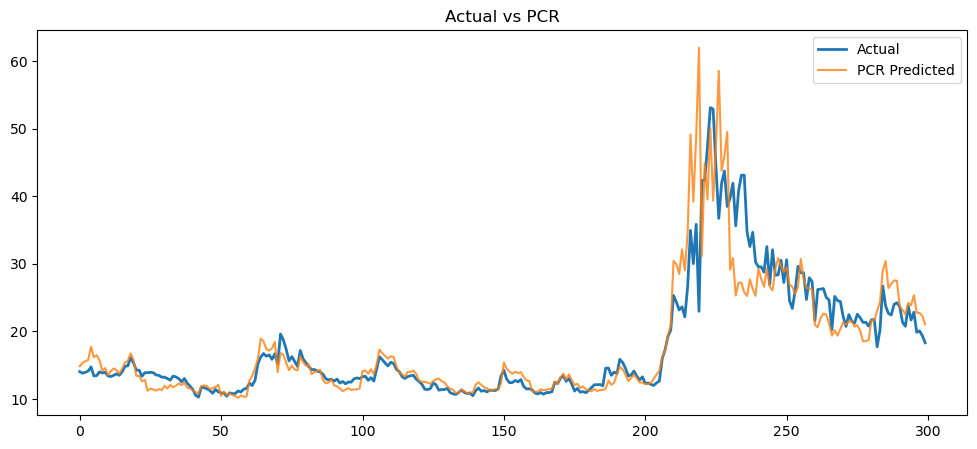





PCR
------------------------------
R²   : 0.2215
RMSE : 0.0610
MAE  : 0.0391





In [7]:
# PCR
y_pred_pcr, reconst_pcr, pcr_components = sliding_walk_forward('PCR',X,y,screened_prices['^AXVI'],TRN_WINDOW,TST_WINDOW)

len_diff= len(y) - len(y_pred_pcr)
focused_plot('PCR',reconst_pcr,screened_prices[len_diff:]['^AXVI'])

print('\n\n')
r2_pcr,rmse_pcr,mae_pcr = compute_stats('PCR',y.values[len_diff:],y_pred_pcr)
print('\n\n')
    

#### **3.2 Partial Least Squares (PLS)**
- Interim results for steps 1-4 in the loop.
- steps 5-10 are not implemented yet.

PLS components = 19


<Figure size 640x480 with 0 Axes>

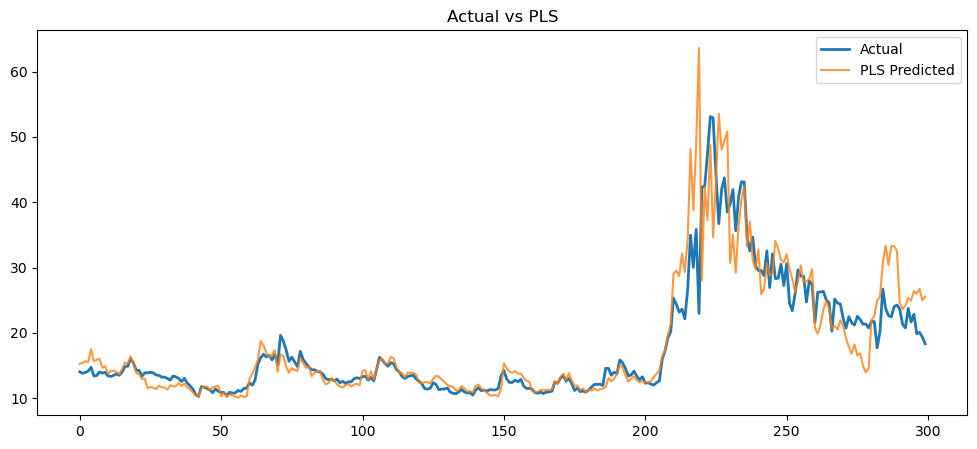





PLS
------------------------------
R²   : 0.1028
RMSE : 0.0655
MAE  : 0.0419





In [8]:
# PLS
n_components = int(np.mean(pcr_components))  # Fady: same as PCR, to be optimised
print('PLS components =' , n_components)

y_pred_pls, reconst_pls, pls_components = sliding_walk_forward('PLS',X,y,screened_prices['^AXVI'],TRN_WINDOW,TST_WINDOW)

len_diff= len(y) - len(y_pred_pls)
focused_plot('PLS',reconst_pls,screened_prices[len_diff:]['^AXVI'])

print('\n\n')
r2_pls,rmse_pls,mae_pls = compute_stats('PLS',y.values[len_diff:],y_pred_pls)
print('\n\n')

#### **3.3 Elastic Net (EN)**
- Interim results for steps 1-4 in the loop.
- steps 5-10 are not implemented yet, step 6 is N/A for EN

<Figure size 640x480 with 0 Axes>

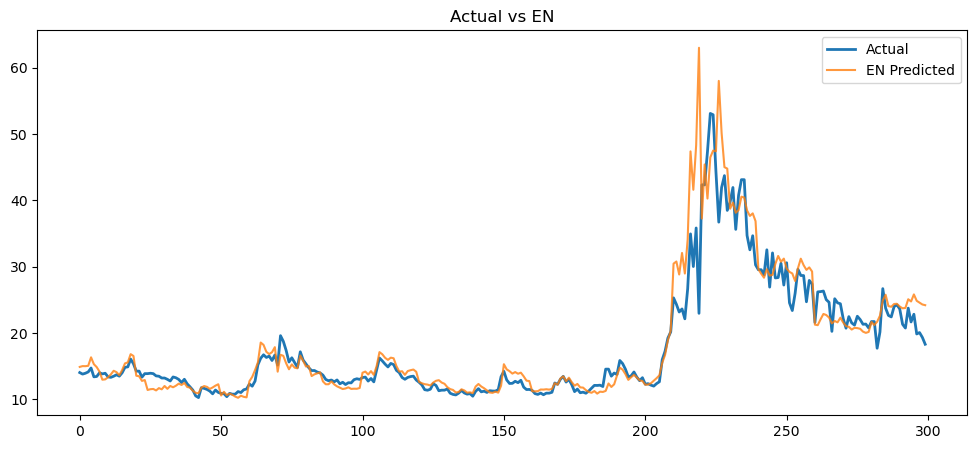





EN
------------------------------
R²   : 0.3165
RMSE : 0.0571
MAE  : 0.0368





In [9]:
# Elastic Net
y_pred_en, reconst_en, en_components = sliding_walk_forward('EN',X,y,screened_prices['^AXVI'],TRN_WINDOW,TST_WINDOW)

len_diff= len(y) - len(y_pred_en)
focused_plot('EN',reconst_en,screened_prices[len_diff:]['^AXVI'])

print('\n\n')
r2_pls,rmse_pls,mae_pls = compute_stats('EN',y.values[len_diff:],y_pred_en)
print('\n\n')

### **4. Hidden Markov Model**

Model design steps:
1. Feature engineering for HMM
2. Training a Hidden Markov Model (HMM)
3. Predicting hidden states from emissions
4. Estimating state prediction accuracy (hand label training set again)



In [10]:
# Fady: HMM utils
def train_hmm(emissions,n_states = HMM_STATES, covariance_type="diag", n_iter=100, random_state=SEED):
  
    X = np.asarray(emissions)

    if X.ndim == 1:
        X = X.reshape(-1, 1)

    model = hmm.GaussianHMM(
        n_components=n_states,
        covariance_type=covariance_type,
        n_iter=n_iter,
        random_state=random_state,
    )

    model.fit(X)

    return model

def predict_states(model, emissions):
    X = np.asarray(emissions)

    if X.ndim == 1:
        X = X.reshape(-1, 1)

    states = model.predict(X)

    return states

def evaluate_state_predictions( true_states, predicted_states):
    metrics = {
        "accuracy": accuracy_score(
            true_states,
            predicted_states
        ),
        "precision_macro": precision_score(
            true_states,
            predicted_states,
            average="macro",
            zero_division=0,
        ),
        "recall_macro": recall_score(
            true_states,
            predicted_states,
            average="macro",
            zero_division=0,
        ),
        "f1_macro": f1_score(
            true_states,
            predicted_states,
            average="macro",
            zero_division=0,
        ),
        "confusion_matrix": confusion_matrix(
            true_states,
            predicted_states,
        ),
        "classification_report": classification_report(
            true_states,
            predicted_states,
            zero_division=0,
        ),
    }

    return metrics

def plot_column_histograms( data, bins=50, figsize=(8, 5)):


    if not isinstance(data, pd.DataFrame):
        data = pd.DataFrame(data)

    for col in data.columns:

        plt.figure(figsize=figsize)

        plt.hist(
            data[col].dropna(),
            bins=bins,
            edgecolor="black"
        )

        plt.title(f"Histogram of {col}")
        plt.xlabel(col)
        plt.ylabel("Frequency")

        plt.grid(True, alpha=0.3)

        plt.show()

def plot_series_and_states(y, states):

    y = np.asarray(y)
    states = np.asarray(states)

    colors = {
        0: "tab:blue",
        1: "tab:orange",
        2: "tab:green"
    }

    fig, ax1 = plt.subplots(figsize=(14, 6))

    # Plot continuous line with segment colours determined by state
    for i in range(len(y) - 1):
        ax1.plot(
            [i, i + 1],
            [y[i], y[i + 1]],
            color=colors.get(states[i], "black"),
            linewidth=1.5
        )

    # Dummy lines for legend
    for state, color in colors.items():
        ax1.plot([], [], color=color, linewidth=2,
                 label=f"Series (State {state})")

    ax1.set_xlabel("Days")
    ax1.set_ylabel("A-VIX")
    ax1.grid(True, alpha=0.3)

    # Secondary axis showing the states
    ax2 = ax1.twinx()

    ax2.step(
        np.arange(len(states)),
        states,
        where="post",
        color="grey",
        #color="white",
        linewidth=2,
        alpha=0.8,
        linestyle="dashed",
        label="State Sequence"
    )

    ax2.set_ylabel("State")
    ax2.set_ylim(-0.5, 2.5)
    ax2.set_yticks([0, 1, 2])

    # Combined legend
    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc="upper left")

    plt.title("3-state HMM model")
    plt.tight_layout()
    plt.show()

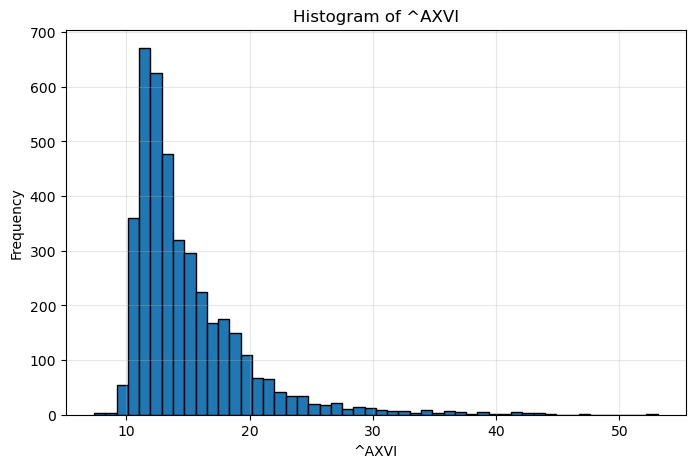

In [11]:
np.random.seed(SEED)
df_p = screened_prices.copy()
df_r = screened_returns.copy()
plot_column_histograms(df_p['^AXVI'])

# Fady: HMM basic feature engineering

# keep the two main features A-VIX and ASX 200 index
clms=['^AXVI', 'STW.AX']
df_p= df_p[clms]
# Add returns
df_p['^AXVI_r'] = df_r['^AXVI']
df_p['STW.AX_r'] = df_r['STW.AX']

# Add EMAs and rolling stats
clms=['^AXVI', 'STW.AX','^AXVI_r']

for clm in clms:
    #df_p['ema3_'+clm] = df_p[clm].ewm(span=3, adjust=False).mean()
    #df_p['ema3_'+clm].bfill(inplace=True)
    #df_p['ema3_pct_'+clm] = df_p['ema3_'+clm].pct_change()
    #df_p['ema3_pct_'+clm].bfill(inplace=True)

    df_p['ema10_'+clm] = df_p[clm].ewm(span=10, adjust=False).mean()
    df_p['ema10_'+clm].bfill(inplace=True)
    df_p['ema10_pct_'+clm] = df_p['ema10_'+clm].pct_change()
    df_p['ema10_pct_'+clm].bfill(inplace=True)
    
    #df_p['std10_'+clm] = df_p[clm].rolling(window=10).std()
    #df_p['std10_'+clm].bfill(inplace=True)
    #df_p['std10_pct_'+clm] = df_p['std10_'+clm].pct_change()
    #df_p['std10_pct_'+clm].bfill(inplace=True)
    
    #df_p['std20_'+clm] = df_p[clm].rolling(window=20).std()
    #df_p['std20_'+clm].bfill(inplace=True)
    #df_p['std20_pct_'+clm] = df_p['std20_'+clm].pct_change()
    #df_p['std20_pct_'+clm].bfill(inplace=True)

# handle unexpected values
replacement_dict = {
    np.inf: df_p[np.isfinite(df_p)].max(),
    -np.inf: df_p[np.isfinite(df_p)].min()
}

df_p.replace(replacement_dict, inplace=True)





In [12]:
# HMM modeling
model = train_hmm( emissions=df_p[clms], n_states=HMM_STATES )
predicted_states = predict_states(  model,  df_p[clms] )

df_p['pred_state'] = predicted_states

# Fady: simple labeling of the training set
df_p['state'] =1
#df_p.loc[cond1, 'state'] = 2
#df_p.loc[cond2, 'state'] = 3
#df_p.loc[df_p['^AXVI']>12, 'state'] = 3
df_p.loc[df_p['^AXVI']>13, 'state'] = 2
df_p.loc[df_p['^AXVI']>16, 'state'] = 0

metrics = evaluate_state_predictions(
    df_p['state'].values,
    df_p['pred_state'].values
)

print('\n')
display(metrics)
print('\n')


# state statistics for identification

#'''
print('\n')
print(df_p.loc[df_p['pred_state']==0, '^AXVI'].median())
print(df_p.loc[df_p['pred_state']==1, '^AXVI'].median())
#print(df_p.loc[df_p['pred_state']==2, '^AXVI'].mean())
#print(df_p.loc[df_p['pred_state']==3, '^AXVI'].mean())

print('\n')
print(df_p.loc[df_p['pred_state']==0, 'ema10_pct_^AXVI'].median())
print(df_p.loc[df_p['pred_state']==1, 'ema10_pct_^AXVI'].median())
#print(df_p.loc[df_p['pred_state']==2, 'ema10_pct_^AXVI'].mean())
#print(df_p.loc[df_p['pred_state']==3, 'ema10_pct_^AXVI'].mean())

#'''


{'accuracy': 0.2403751233958539,
 'precision_macro': 0.3893028935800835,
 'recall_macro': 0.26949403565109803,
 'f1_macro': 0.30730679984988724,
 'confusion_matrix': array([[ 632,  516,    0],
        [   8,  145, 1638],
        [  13,  903,  197]]),
 'classification_report': '              precision    recall  f1-score   support\n\n           0       0.97      0.55      0.70      1148\n           1       0.09      0.08      0.09      1791\n           2       0.11      0.18      0.13      1113\n\n    accuracy                           0.24      4052\n   macro avg       0.39      0.27      0.31      4052\nweighted avg       0.34      0.24      0.27      4052\n'}





21.360000610351562
15.050000190734863


0.0029880864230509285
-0.0023709232821589876


<Figure size 640x480 with 0 Axes>

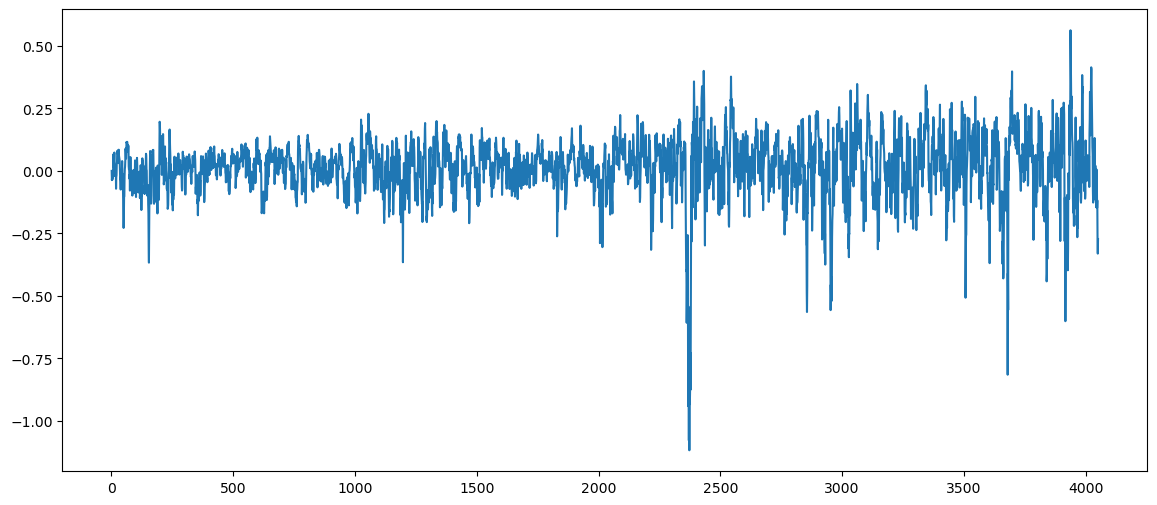

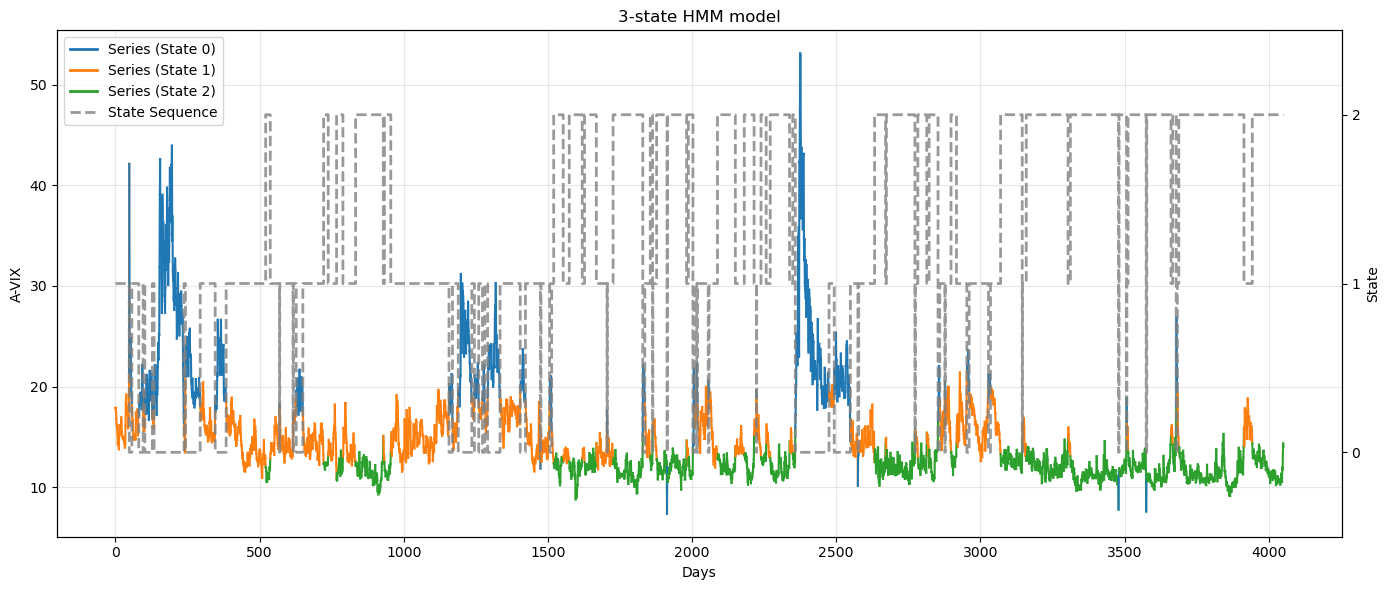

In [13]:
# Add some visualisation



plt.clf()
plt.figure(figsize=(14,6))
df_p['ema10_'+'STW.AX'] = df_p['STW.AX'].ewm(span=10, adjust=False).mean()
plt.plot(df_p['ema10_'+'STW.AX'].diff().values)
plt.show()

print('\n\n')
plot_series_and_states(df_p['^AXVI'], df_p['pred_state'])


### **5. Expanding window Walk-forward loop for HMM**

1. Generate the train and test pairs for each iteration.
2. Fit the HMM model on the training window data
3. Apply state based EN (or PCR, PLS) fiting to training window
4. Predict the test window HMM states
5. Predict A-VIX percentage change
6. Reconstruct the A-VIX level from the predicted precentage change
7. Calculate different tracking error metrics on test window.
8. Calculate the state-based individual securties coeffcients from the factor coefficents.
9. Define state-based portfolio weight constraints guided by the regressions coeffcients after normalisation.
10. Conduct state-based QP weight optimsation to minise tracking error in training window subject to protfolio constraints.
11. Predict portfolio returns over the test window
12. Calculate trading metrics for the rebalancing at the end of the test window

### **References:**

[1] Dhingra, V., Sharma, A., & Goel, A. _"Index Tracking in Financial Markets: A Comprehensive Review of Optimization, Statistical, and Data-Driven Modeling Approaches"_. Knowledge-Based Systems (2026), 343, 116011. https://doi.org/10.1016/j.knosys.2026.116011



